<a href="https://colab.research.google.com/github/kunjpatel00987/Data-Visualization/blob/main/Data_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
df = pd.read_excel('/content/drive/MyDrive/[5442] EcoMoveMobility.xlsx')
df.head()

,Record_ID,Date,City,Country,Transport_Mode,Route_Type,Weather,Event_Day,Passengers,Trips,Average_Delay_Minutes,On_Time_Percentage,Ticket_Revenue_EUR,Operating_Cost_EUR,CO2_Saved_KG,Energy_Consumption_KWh,Customer_Rating,Accessibility_Complaints
0,EM-00001,45747,Paris,France,Tram,Tourist Zone,Cloudy,Yes,22946,101,3.2,85.1,58846.34,47796.73,2005.0,1446.4,4.4,26
1,EM-00002,45717,Paris,France,Tram,University Area,Cloudy,No,9417,59,1.5,90.1,24578.85,20708.01,824.3,495.1,4.7,7
2,EM-00003,45882,Rotterdam,Netherlands,Tram,Airport Connector,Clear,No,6467,38,3.4,87.9,15168.68,14129.41,693.1,405.8,4.4,7
3,EM-00004,45504,Lyon,France,Tram,University Area,Clear,Yes,5218,33,6.9,74.5,14172.20,11945.52,600.1,278.1,3.9,7
4,EM-00005,45578,Amsterdam,Netherlands,Metro,Tourist Zone,Cloudy,No,10258,19,3.6,83.2,27534.92,28846.82,1392.4,580.5,4.4,12


In [ ]:
import pandas as pd

df = pd.read_excel('/content/drive/MyDrive/[5442] EcoMoveMobility.xlsx')

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Dates are Excel serial numbers -> convert to real dates
df["Date"] = pd.to_datetime(df["Date"], unit="D", origin="1899-12-30")
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())

# New columns
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Net_Result_EUR"] = df["Ticket_Revenue_EUR"] - df["Operating_Cost_EUR"]
df["Complaints_per_1000"] = df["Accessibility_Complaints"] / df["Passengers"] * 1000

print("Records making a loss:", f"{(df['Net_Result_EUR'] < 0).mean():.1%}")
df[["Date", "Year", "Month", "Net_Result_EUR", "Complaints_per_1000"]].head()

Shape: (5000, 18)
Missing values: 0
Duplicate rows: 0
Date range: 2024-01-01 to 2025-12-31
Records making a loss: 45.4%


,Date,Year,Month,Net_Result_EUR,Complaints_per_1000
0,2025-03-31,2025,3,11049.61,1.133095
1,2025-03-01,2025,3,3870.84,0.743337
2,2025-08-13,2025,8,1039.27,1.082418
3,2024-07-31,2024,7,2226.68,1.341510
4,2024-10-13,2024,10,-1311.90,1.169819


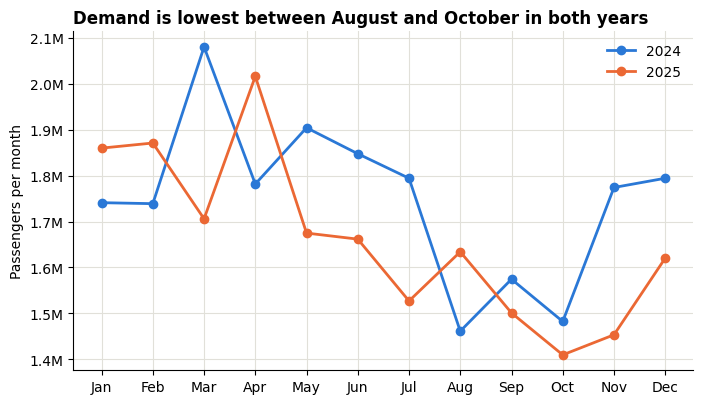

In [ ]:
import matplotlib.pyplot as plt

m = df.groupby(["Year", "Month"])["Passengers"].sum().unstack(0)
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(m.index, m[2024], color="#2a78d6", lw=2, marker="o", label="2024")
ax.plot(m.index, m[2025], color="#eb6834", lw=2, marker="o", label="2025")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(months)
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1e6:.1f}M")
ax.set_ylabel("Passengers per month")
ax.set_title("Demand is lowest between August and October in both years", loc="left", fontweight="bold")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e1e0d9")
plt.show()

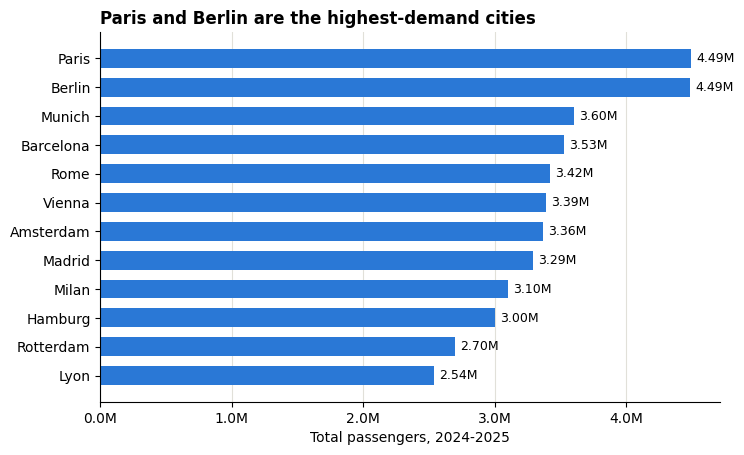

City
Paris        4492481
Berlin       4487351
Munich       3603328
Barcelona    3526320
Rome         3418626
Vienna       3388470
Amsterdam    3364412
Madrid       3289904
Milan        3100424
Hamburg      3004164
Rotterdam    2697713
Lyon         2536528
Name: Passengers, dtype: int64


In [ ]:
city = df.groupby("City")["Passengers"].sum().sort_values()

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(city.index, city.values, color="#2a78d6", height=0.65)
for y, v in enumerate(city.values):
    ax.text(v + 4e4, y, f"{v/1e6:.2f}M", va="center", fontsize=9)
ax.xaxis.set_major_formatter(lambda v, _: f"{v/1e6:.1f}M")
ax.set_xlabel("Total passengers, 2024-2025")
ax.set_title("Paris and Berlin are the highest-demand cities", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e1e0d9")
ax.set_axisbelow(True)
plt.show()

print(city.sort_values(ascending=False))

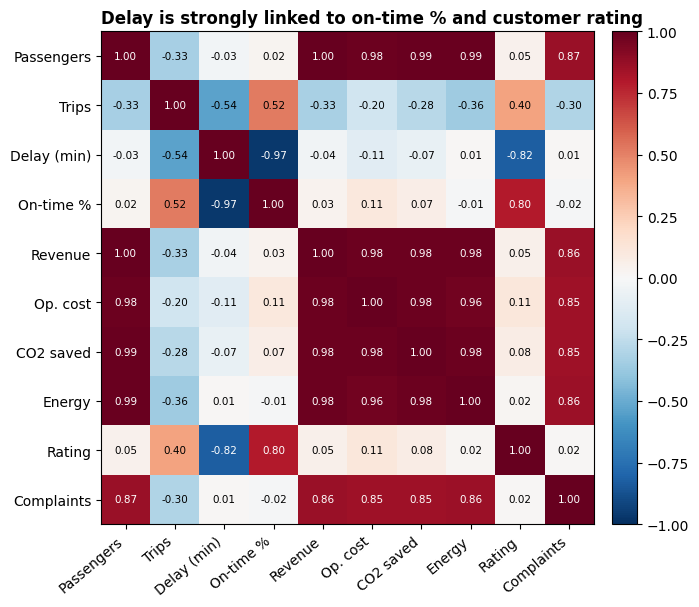

In [ ]:
cols = ["Passengers", "Trips", "Average_Delay_Minutes", "On_Time_Percentage",
        "Ticket_Revenue_EUR", "Operating_Cost_EUR", "CO2_Saved_KG",
        "Energy_Consumption_KWh", "Customer_Rating", "Accessibility_Complaints"]
labels = ["Passengers", "Trips", "Delay (min)", "On-time %", "Revenue",
          "Op. cost", "CO2 saved", "Energy", "Rating", "Complaints"]
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.4))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(labels, rotation=40, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(labels)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03)
ax.set_title("Delay is strongly linked to on-time % and customer rating",
             loc="left", fontweight="bold")
plt.show()

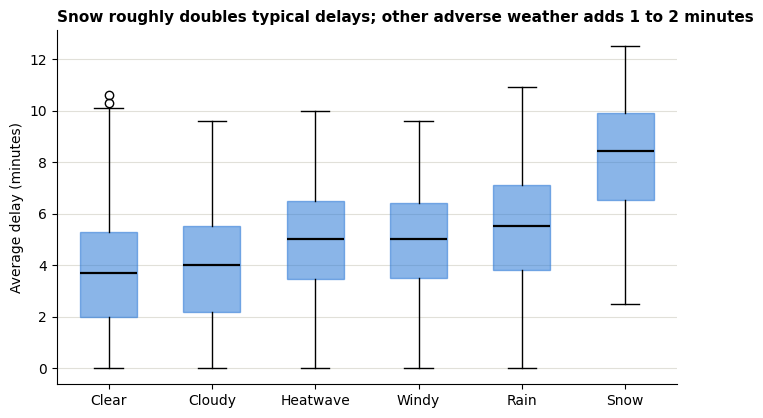

           count  mean   std  min   25%   50%  75%   max
Weather                                                 
Clear     2071.0  3.71  2.15  0.0  2.00  3.70  5.3  10.6
Cloudy    1293.0  3.89  2.15  0.0  2.20  4.00  5.5   9.6
Heatwave   243.0  4.91  2.21  0.0  3.45  5.00  6.5  10.0
Windy      306.0  4.86  2.10  0.0  3.50  5.00  6.4   9.6
Rain       905.0  5.40  2.26  0.0  3.80  5.50  7.1  10.9
Snow       182.0  8.14  2.28  2.5  6.52  8.45  9.9  12.5


In [ ]:
order = df.groupby("Weather")["Average_Delay_Minutes"].median().sort_values().index
data = [df.loc[df["Weather"] == w, "Average_Delay_Minutes"] for w in order]

fig, ax = plt.subplots(figsize=(8, 4.6))
bp = ax.boxplot(data, patch_artist=True, widths=0.55,
                medianprops=dict(color="black", lw=1.6))
for box in bp["boxes"]:
    box.set(facecolor="#2a78d6", alpha=0.55, edgecolor="#2a78d6")
ax.set_xticklabels(order)
ax.set_ylabel("Average delay (minutes)")
ax.set_title("Snow roughly doubles typical delays; other adverse weather adds 1 to 2 minutes",
             loc="left", fontweight="bold", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e1e0d9")
ax.set_axisbelow(True)
plt.show()

print(df.groupby("Weather")["Average_Delay_Minutes"]
        .describe().sort_values("50%").round(2))

In [ ]:
df["Net_Result_EUR"] = df["Ticket_Revenue_EUR"] - df["Operating_Cost_EUR"]

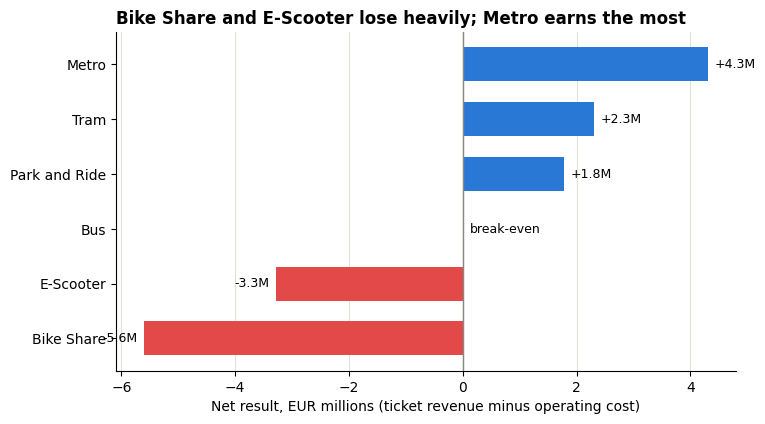

Transport_Mode
Bike Share         5.2
E-Scooter          7.4
Bus              100.1
Metro            106.2
Tram             117.3
Park and Ride    121.5
dtype: float64
Overall: 99.6 %


In [ ]:
net = (df.groupby("Transport_Mode")["Net_Result_EUR"].sum() / 1e6).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.4))
colors = ["#2a78d6" if v >= 0 else "#e34948" for v in net.values]
ax.barh(net.index, net.values, color=colors, height=0.62)
for y, v in enumerate(net.values):
    label = "break-even" if abs(v) < 0.05 else f"{v:+.1f}M"
    ax.text(v + (0.12 if v >= 0 else -0.12), y, label, va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color="#898781", lw=1)
ax.set_xlabel("Net result, EUR millions (ticket revenue minus operating cost)")
ax.set_title("Bike Share and E-Scooter lose heavily; Metro earns the most",
             loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e1e0d9")
ax.set_axisbelow(True)
plt.show()

rev = df.groupby("Transport_Mode")["Ticket_Revenue_EUR"].sum()
cost = df.groupby("Transport_Mode")["Operating_Cost_EUR"].sum()
print((rev / cost * 100).round(1).sort_values())   # cost recovery %
print("Overall:", round(rev.sum() / cost.sum() * 100, 1), "%")

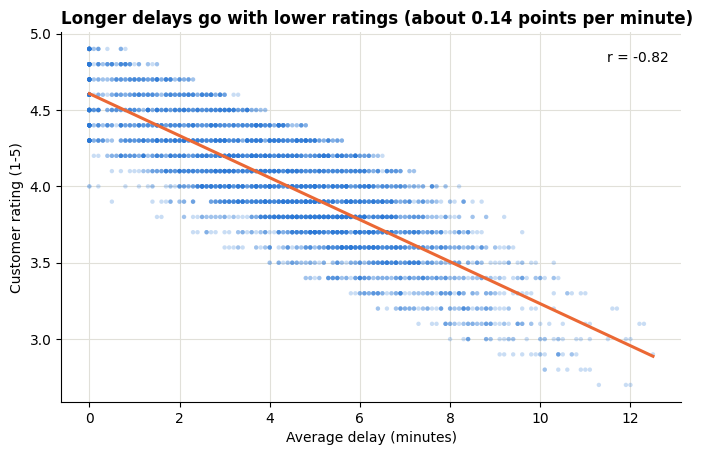

r = -0.821, slope = -0.138 rating points per minute


In [ ]:
import numpy as np

x = df["Average_Delay_Minutes"]
y = df["Customer_Rating"]
slope, intercept = np.polyfit(x, y, 1)
r = np.corrcoef(x, y)[0, 1]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(x, y, s=10, color="#2a78d6", alpha=0.25, edgecolors="none")
xs = np.array([x.min(), x.max()])
ax.plot(xs, slope * xs + intercept, color="#eb6834", lw=2.2)
ax.text(0.98, 0.95, f"r = {r:.2f}", transform=ax.transAxes, ha="right", va="top")
ax.set_xlabel("Average delay (minutes)")
ax.set_ylabel("Customer rating (1-5)")
ax.set_title("Longer delays go with lower ratings (about 0.14 points per minute)",
             loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e1e0d9")
ax.set_axisbelow(True)
plt.show()

print(f"r = {r:.3f}, slope = {slope:.3f} rating points per minute")

In [ ]:
comp = df.groupby("Transport_Mode")["Accessibility_Complaints"].sum()
pax = df.groupby("Transport_Mode")["Passengers"].sum()
rate = (comp / pax * 1000).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(rate.index, rate.values, color="#2a78d6", height=0.62)
for y, v in enumerate(rate.values):
    ax.text(v + 0.02, y, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlim(0, 2.0)
ax.set_xlabel("Accessibility complaints per 1,000 passengers")
ax.set_title("Complaint rates are similar across modes; E-Scooter and Bus are highest",
             loc="left", fontweight="bold", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e1e0d9")
ax.set_axisbelow(True)
plt.show()

print(comp.sort_values())   # raw counts, for comparison
print((comp / comp.sum() * 100).round(1))

NameError: name 'df' is not defined

In [ ]:
# ===================== COM7021 Task 1: Interactive dashboard =====================
# Run AFTER the data preparation cell (needs the dataframe `df`).
# Colab already has plotly and ipywidgets installed.
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display, HTML

BLUE, RED = "#2a78d6", "#e34948"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

# ---- prepare a working copy (safe even if some helper columns are missing) ----
d = df.copy()
if not pd.api.types.is_datetime64_any_dtype(d["Date"]):
    d["Date"] = pd.to_datetime(d["Date"], unit="D", origin="1899-12-30")
d["YearMonth"] = d["Date"].dt.to_period("M").dt.to_timestamp()
if "Net_Result_EUR" not in d.columns:
    d["Net_Result_EUR"] = d["Ticket_Revenue_EUR"] - d["Operating_Cost_EUR"]

MONTHS = sorted(d["YearMonth"].unique())
MONTH_LABELS = [pd.Timestamp(m).strftime("%b %Y") for m in MONTHS]


def filter_data(country, city, mode, route, weather, event, start, end, skip=None):
    """Apply every filter except the one named in `skip` (used for context charts)."""
    x = d
    for col, val in [("Country", country), ("City", city), ("Transport_Mode", mode),
                     ("Route_Type", route), ("Weather", weather), ("Event_Day", event)]:
        if val != "All" and col != skip:
            x = x[x[col] == val]
    s, e = pd.to_datetime(start, format="%b %Y"), pd.to_datetime(end, format="%b %Y")
    return x[(x["YearMonth"] >= s) & (x["YearMonth"] <= e)]


def kpi_html(x):
    pax = x["Passengers"].sum()
    net = x["Net_Result_EUR"].sum() / 1e6
    tiles = [
        ("Passengers", f"{pax/1e6:.2f}M"),
        ("Avg delay (min)", f"{x['Average_Delay_Minutes'].mean():.2f}"),
        ("On-time %", f"{x['On_Time_Percentage'].mean():.1f}%"),
        ("Avg rating (1-5)", f"{x['Customer_Rating'].mean():.2f}"),
        ("Net result (EUR)", f"{net:+.2f}M"),
        ("CO2 saved", f"{x['CO2_Saved_KG'].sum()/1000:,.0f} t"),
        ("Complaints/1,000 pax", f"{x['Accessibility_Complaints'].sum()/pax*1000:.2f}"),
    ]
    cells = "".join(
        f"<div style='flex:1 1 0;min-width:105px;padding:8px 10px;border:1px solid {GRID};"
        f"border-radius:8px;background:#fcfcfb'>"
        f"<div style='font-size:11px;color:{INK2};white-space:nowrap'>{t}</div>"
        f"<div style='font-size:19px;font-weight:600;color:{INK}'>{v}</div></div>"
        for t, v in tiles)
    note = (f"<div style='font-size:12px;color:{INK2};margin:4px 0 8px'>"
            f"{len(x):,} records selected. Delay, on-time % and rating are record averages.</div>")
    return (f"{note}<div style='display:flex;gap:6px;font-family:system-ui,"
            f"sans-serif'>{cells}</div>")


def hbar(fig, row, col, series, fmt, selected="All", signed_colors=False, zero_line=False):
    """Horizontal bar. Selected category stays solid; the others are faded for context."""
    vals = list(series.values)
    if signed_colors:
        colors = [BLUE if v >= 0 else RED for v in vals]
    else:
        colors = [BLUE] * len(vals)
    opacity = [1.0 if selected in ("All", name) else 0.3 for name in series.index]
    fig.add_trace(go.Bar(
        x=vals, y=list(series.index), orientation="h",
        marker=dict(color=colors, opacity=opacity),
        text=[fmt.format(v) for v in vals], textposition="outside", cliponaxis=False,
        hovertemplate="%{y}: %{text}<extra></extra>"), row=row, col=col)
    lo = min(0, min(vals)) * 1.35
    hi = max(0, max(vals)) * 1.18
    fig.update_xaxes(range=[lo, hi], row=row, col=col)
    if zero_line:
        fig.add_vline(x=0, line_color="#898781", line_width=1, row=row, col=col)


def build(country="All", city="All", mode="All", route="All", weather="All",
          event="All", start=MONTH_LABELS[0], end=MONTH_LABELS[-1]):
    args = dict(country=country, city=city, mode=mode, route=route, weather=weather,
                event=event, start=start, end=end)
    x = filter_data(**args)                          # everything filtered: tiles + trend
    if x.empty:
        return "<b>No records match these filters.</b>", None
    x_city = filter_data(**args, skip="City")        # city charts ignore the city filter
    x_mode = filter_data(**args, skip="Transport_Mode")
    x_wthr = filter_data(**args, skip="Weather")

    fig = make_subplots(
        rows=3, cols=2, vertical_spacing=0.11, horizontal_spacing=0.16,
        subplot_titles=("Demand: passengers per month",
                        "Demand: passengers by city (thousands)",
                        "Reliability: average delay by weather (min)",
                        "Investment: net result by mode (EUR M)",
                        "Sustainability: CO2 saved by mode (tonnes)",
                        "Accessibility: complaints per 1,000 passengers, by city"))

    # 1 time series
    m = x.groupby("YearMonth")["Passengers"].sum()
    fig.add_trace(go.Scatter(x=m.index, y=m.values, mode="lines+markers",
                             line=dict(color=BLUE, width=2), marker=dict(size=7),
                             hovertemplate="%{x|%b %Y}: %{y:,.0f}<extra></extra>"), row=1, col=1)
    fig.update_yaxes(rangemode="tozero", row=1, col=1)

    # 2 passengers by city (thousands)
    hbar(fig, 1, 2, (x_city.groupby("City")["Passengers"].sum() / 1e3).sort_values(),
         "{:,.0f}", selected=city)
    # 3 delay by weather
    hbar(fig, 2, 1, x_wthr.groupby("Weather")["Average_Delay_Minutes"].mean().sort_values(),
         "{:.1f}", selected=weather)
    # 4 net result by mode (red = loss)
    net = (x_mode.groupby("Transport_Mode")["Net_Result_EUR"].sum() / 1e6).sort_values()
    hbar(fig, 2, 2, net, "{:+.2f}" if net.abs().max() < 1 else "{:+.1f}",
         selected=mode, signed_colors=True, zero_line=True)
    # 5 CO2 saved by mode
    hbar(fig, 3, 1, (x_mode.groupby("Transport_Mode")["CO2_Saved_KG"].sum() / 1000).sort_values(),
         "{:,.0f}", selected=mode)
    # 6 complaints per 1,000 passengers by city
    rate = (x_city.groupby("City")["Accessibility_Complaints"].sum()
            / x_city.groupby("City")["Passengers"].sum() * 1000).sort_values()
    hbar(fig, 3, 2, rate, "{:.2f}", selected=city)

    fig.update_layout(
        height=950, width=1050, showlegend=False, template="plotly_white",
        font=dict(family="system-ui, sans-serif", size=12, color=INK2),
        margin=dict(l=20, r=40, t=60, b=30), plot_bgcolor="#fcfcfb")
    fig.update_xaxes(gridcolor=GRID, zeroline=False)
    fig.update_yaxes(gridcolor=GRID)
    return kpi_html(x), fig


def render(**kw):
    html, fig = build(**kw)
    display(HTML(html))
    if fig is not None:
        fig.show()


# ------------------------------- controls -------------------------------------
def dd(label, values):
    opts = [("All", "All")] + [(v, v) for v in sorted(values)]
    return widgets.Dropdown(options=opts, description=label, value="All",
                            style={"description_width": "70px"},
                            layout=widgets.Layout(width="220px"))

controls = dict(
    country=dd("Country", d["Country"].unique()),
    city=dd("City", d["City"].unique()),
    mode=dd("Mode", d["Transport_Mode"].unique()),
    route=dd("Route type", d["Route_Type"].unique()),
    weather=dd("Weather", d["Weather"].unique()),
    event=widgets.Dropdown(options=[("All", "All"), ("Event day", "Yes"), ("Normal day", "No")],
                           value="All", description="Event day",
                           style={"description_width": "70px"},
                           layout=widgets.Layout(width="220px")),
    start=widgets.Dropdown(options=MONTH_LABELS, value=MONTH_LABELS[0], description="From",
                           style={"description_width": "70px"},
                           layout=widgets.Layout(width="220px")),
    end=widgets.Dropdown(options=MONTH_LABELS, value=MONTH_LABELS[-1], description="To",
                         style={"description_width": "70px"},
                         layout=widgets.Layout(width="220px")),
)

title = widgets.HTML(
    "<h3 style='margin:0 0 4px;font-family:system-ui,sans-serif'>EcoMove City Transport "
    "Authority: management dashboard</h3>"
    f"<div style='font-size:12px;color:{INK2};margin-bottom:6px'>Filters apply to every tile. "
    "In a chart grouped by the filtered field, the selected value is solid and the others "
    "are faded for comparison.</div>")
row1 = widgets.HBox([controls[k] for k in ("country", "city", "mode", "route")])
row2 = widgets.HBox([controls[k] for k in ("weather", "event", "start", "end")])
out = widgets.interactive_output(render, controls)
display(widgets.VBox([title, row1, row2, out]))

In [ ]:
# ===================== COM7021 Task 1: Interactive dashboard =====================
# Run AFTER the data preparation cell (needs the dataframe `df`).
# Uses matplotlib + ipywidgets only (both already installed in Colab).
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import ipywidgets as widgets
from IPython.display import display, HTML

BLUE, RED = "#2a78d6", "#e34948"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"

# ---- prepare a working copy (safe even if some helper columns are missing) ----
d = df.copy()
if not pd.api.types.is_datetime64_any_dtype(d["Date"]):
    d["Date"] = pd.to_datetime(d["Date"], unit="D", origin="1899-12-30")
d["YearMonth"] = d["Date"].dt.to_period("M").dt.to_timestamp()
if "Net_Result_EUR" not in d.columns:
    d["Net_Result_EUR"] = d["Ticket_Revenue_EUR"] - d["Operating_Cost_EUR"]

MONTHS = sorted(d["YearMonth"].unique())
MONTH_LABELS = [pd.Timestamp(m).strftime("%b %Y") for m in MONTHS]


def filter_data(country, city, mode, route, weather, event, start, end, skip=None):
    """Apply every filter except the one named in `skip` (used for context charts)."""
    x = d
    for col, val in [("Country", country), ("City", city), ("Transport_Mode", mode),
                     ("Route_Type", route), ("Weather", weather), ("Event_Day", event)]:
        if val != "All" and col != skip:
            x = x[x[col] == val]
    s, e = pd.to_datetime(start, format="%b %Y"), pd.to_datetime(end, format="%b %Y")
    return x[(x["YearMonth"] >= s) & (x["YearMonth"] <= e)]


def kpi_html(x):
    pax = x["Passengers"].sum()
    net = x["Net_Result_EUR"].sum() / 1e6
    tiles = [
        ("Passengers", f"{pax/1e6:.2f}M"),
        ("Avg delay (min)", f"{x['Average_Delay_Minutes'].mean():.2f}"),
        ("On-time %", f"{x['On_Time_Percentage'].mean():.1f}%"),
        ("Avg rating (1-5)", f"{x['Customer_Rating'].mean():.2f}"),
        ("Net result (EUR)", f"{net:+.2f}M"),
        ("CO2 saved", f"{x['CO2_Saved_KG'].sum()/1000:,.0f} t"),
        ("Complaints/1,000 pax", f"{x['Accessibility_Complaints'].sum()/pax*1000:.2f}"),
    ]
    cells = "".join(
        f"<div style='flex:1 1 0;min-width:105px;padding:8px 10px;border:1px solid {GRID};"
        f"border-radius:8px;background:{SURFACE}'>"
        f"<div style='font-size:11px;color:{INK2};white-space:nowrap'>{t}</div>"
        f"<div style='font-size:19px;font-weight:600;color:{INK}'>{v}</div></div>"
        for t, v in tiles)
    note = (f"<div style='font-size:12px;color:{MUTED};margin:4px 0 8px'>"
            f"{len(x):,} records selected. Delay, on-time % and rating are record averages.</div>")
    return (f"{note}<div style='display:flex;gap:6px;font-family:system-ui,"
            f"sans-serif'>{cells}</div>")


def style(ax, title):
    ax.set_title(title, loc="left", fontsize=10.5, fontweight="bold", color=INK)
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis="x", color=GRID, lw=0.7)
    ax.set_axisbelow(True)


def hbar(ax, series, fmt, title, selected="All", signed=False):
    """Horizontal bars. Selected category stays solid; the others are faded for context."""
    names, vals = list(series.index), [float(v) for v in series.values]
    colors = [BLUE if (not signed or v >= 0) else RED for v in vals]
    bars = ax.barh(names, vals, color=colors, height=0.68)
    for b, n in zip(bars, names):
        b.set_alpha(1.0 if selected in ("All", n) else 0.3)
    lo, hi = min(0, min(vals)), max(0, max(vals))
    span = (hi - lo) or 1.0
    for n, v in zip(names, vals):
        ax.text(v + (0.015 if v >= 0 else -0.015) * span, n, fmt.format(v), va="center",
                ha="left" if v >= 0 else "right", fontsize=8.5, color=INK2)
    ax.set_xlim(lo - 0.2 * span if lo < 0 else 0, hi + 0.2 * span)
    if signed:
        ax.axvline(0, color=MUTED, lw=1)
    style(ax, title)
    ax.grid(axis="y", visible=False)


def build(country="All", city="All", mode="All", route="All", weather="All",
          event="All", start=MONTH_LABELS[0], end=MONTH_LABELS[-1]):
    args = dict(country=country, city=city, mode=mode, route=route, weather=weather,
                event=event, start=start, end=end)
    x = filter_data(**args)                          # everything filtered: tiles + trend
    if x.empty:
        return "<b>No records match these filters.</b>", None
    x_city = filter_data(**args, skip="City")        # city charts ignore the city filter
    x_mode = filter_data(**args, skip="Transport_Mode")
    x_wthr = filter_data(**args, skip="Weather")

    fig, axes = plt.subplots(3, 2, figsize=(12, 11), facecolor=SURFACE)
    fig.subplots_adjust(left=0.10, right=0.97, top=0.96, bottom=0.05, hspace=0.42, wspace=0.42)
    (a1, a2), (a3, a4), (a5, a6) = axes

    # 1 time series
    m = x.groupby("YearMonth")["Passengers"].sum()
    a1.plot(m.index, m.values, color=BLUE, lw=2, marker="o", ms=5, markeredgecolor=SURFACE)
    a1.set_ylim(bottom=0)
    a1.yaxis.set_major_formatter(FuncFormatter(
        lambda v, _: f"{v/1e6:.1f}M" if v >= 1e6 else f"{v/1e3:.0f}k"))
    a1.xaxis.set_major_locator(mdates.MonthLocator(interval=6 if len(m) > 12 else 2))
    a1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    style(a1, "Demand: passengers per month")
    a1.grid(axis="y", color=GRID, lw=0.7)

    # 2 passengers by city (thousands)
    hbar(a2, (x_city.groupby("City")["Passengers"].sum() / 1e3).sort_values(), "{:,.0f}",
         "Demand: passengers by city (thousands)", selected=city)
    # 3 delay by weather
    hbar(a3, x_wthr.groupby("Weather")["Average_Delay_Minutes"].mean().sort_values(), "{:.1f}",
         "Reliability: average delay by weather (min)", selected=weather)
    # 4 net result by mode (red = loss)
    net = (x_mode.groupby("Transport_Mode")["Net_Result_EUR"].sum() / 1e6).sort_values()
    hbar(a4, net, "{:+.2f}" if net.abs().max() < 1 else "{:+.1f}",
         "Investment: net result by mode (EUR M)", selected=mode, signed=True)
    # 5 CO2 saved by mode
    hbar(a5, (x_mode.groupby("Transport_Mode")["CO2_Saved_KG"].sum() / 1000).sort_values(),
         "{:,.0f}", "Sustainability: CO2 saved by mode (tonnes)", selected=mode)
    # 6 complaints per 1,000 passengers by city
    rate = (x_city.groupby("City")["Accessibility_Complaints"].sum()
            / x_city.groupby("City")["Passengers"].sum() * 1000).sort_values()
    hbar(a6, rate, "{:.2f}", "Accessibility: complaints per 1,000 passengers, by city",
         selected=city)
    return kpi_html(x), fig


def render(**kw):
    html, fig = build(**kw)
    display(HTML(html))
    if fig is not None:
        display(fig)
        plt.close(fig)


# ------------------------------- controls -------------------------------------
def dd(label, values):
    opts = [("All", "All")] + [(v, v) for v in sorted(values)]
    return widgets.Dropdown(options=opts, description=label, value="All",
                            style={"description_width": "70px"},
                            layout=widgets.Layout(width="220px"))

controls = dict(
    country=dd("Country", d["Country"].unique()),
    city=dd("City", d["City"].unique()),
    mode=dd("Mode", d["Transport_Mode"].unique()),
    route=dd("Route type", d["Route_Type"].unique()),
    weather=dd("Weather", d["Weather"].unique()),
    event=widgets.Dropdown(options=[("All", "All"), ("Event day", "Yes"), ("Normal day", "No")],
                           value="All", description="Event day",
                           style={"description_width": "70px"},
                           layout=widgets.Layout(width="220px")),
    start=widgets.Dropdown(options=MONTH_LABELS, value=MONTH_LABELS[0], description="From",
                           style={"description_width": "70px"},
                           layout=widgets.Layout(width="220px")),
    end=widgets.Dropdown(options=MONTH_LABELS, value=MONTH_LABELS[-1], description="To",
                         style={"description_width": "70px"},
                         layout=widgets.Layout(width="220px")),
)

title = widgets.HTML(
    "<h3 style='margin:0 0 4px;font-family:system-ui,sans-serif'>EcoMove City Transport "
    "Authority: management dashboard</h3>"
    f"<div style='font-size:12px;color:{MUTED};margin-bottom:6px'>Filters apply to every tile. "
    "In a chart grouped by the filtered field, the selected value is solid and the others "
    "are faded for comparison.</div>")
row1 = widgets.HBox([controls[k] for k in ("country", "city", "mode", "route")])
row2 = widgets.HBox([controls[k] for k in ("weather", "event", "start", "end")])
out = widgets.interactive_output(render, controls)
display(widgets.VBox([title, row1, row2, out]))